# Lung Cancer Image Classification: A Beginner-Friendly Training Notebook

This notebook compares four ImageNet-pretrained convolutional neural networks (CNNs) and a Swin Transformer on the lung-cancer image dataset used by the existing Drive 2 training notebook. It is designed for Google Colab, where the original dataset is stored in Google Drive.

The goal is to predict the image's dataset class. This is an educational image-classification experiment, not a medical diagnostic tool.

## Workflow

1. Configure the environment and reproducibility settings.
2. Load and inspect the existing train, validation, and test folders.
3. Build and train the same four CNNs plus a Swin Transformer.
4. Select a model using validation results, then report test-set metrics.
5. Save model weights, histories, tables, predictions, and plots in a unique run folder.

> Run the cells from top to bottom. Training five pretrained models can take considerable time and may download ImageNet weights the first time.


## 1. Environment and dependencies

The original project uses TensorFlow/Keras. The next cell installs KerasHub for the pretrained Swin Transformer; set deterministic-operation environment variables before importing TensorFlow.


In [ ]:
%pip install -q keras-hub

In [1]:
import os

# These are read by TensorFlow when it initializes.
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

import json
import platform
import random
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)

print("Core libraries imported.")

Core libraries imported.


### Check software and hardware

TensorFlow can use a GPU when Colab has GPU acceleration enabled. The reported CUDA and cuDNN versions describe the TensorFlow build; an available GPU is also required for GPU execution.


In [2]:
print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

build_info = tf.sysconfig.get_build_info()
print("CUDA in TensorFlow build:", build_info.get("cuda_version", "not available"))
print("cuDNN in TensorFlow build:", build_info.get("cudnn_version", "not available"))

gpu_devices = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpu_devices))
print("GPU devices:", gpu_devices if gpu_devices else "None; training will use the CPU")

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
Matplotlib: 3.10.0
CUDA in TensorFlow build: 12.5.1
cuDNN in TensorFlow build: 9
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Reproducibility and configuration

The values below retain the original experiment's seed, image size, batch size, learning rate, and epoch limit. This notebook uses the existing pre-split folders rather than creating a new split. Deterministic operations and fixed seeds improve repeatability, but exact results are not guaranteed across hardware, TensorFlow/CUDA versions, or operations without deterministic implementations.


In [3]:
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.3
EARLY_STOPPING_PATIENCE = 3
NUM_PARALLEL_CALLS = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Random seeds set to", SEED)
print("Deterministic TensorFlow operations enabled where supported.")

Random seeds set to 42
Deterministic TensorFlow operations enabled where supported.


### Connect Google Drive

The paths below match the existing Drive 2 augmented-dataset notebook. Mounting Drive gives Colab access to those folders and to the output location.


In [4]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
DATASET_ROOT = Path("/content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V4")
TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

# Each run gets a new timestamped folder so previous results are not overwritten.
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RESULTS_ROOT = Path("/content/drive/MyDrive/Lung_Cancer_Classification_Results")
RUN_DIR = RESULTS_ROOT / f"run_{RUN_ID}"
MODELS_DIR = RUN_DIR / "models"
HISTORIES_DIR = RUN_DIR / "histories"
METRICS_DIR = RUN_DIR / "metrics"
GRAPHS_DIR = RUN_DIR / "graphs"
PREDICTIONS_DIR = RUN_DIR / "predictions"
CHECKPOINTS_DIR = RUN_DIR / "checkpoints"
CONFIG_DIR = RUN_DIR / "experiment_config"

for output_dir in (
    MODELS_DIR,
    HISTORIES_DIR,
    METRICS_DIR,
    GRAPHS_DIR,
    PREDICTIONS_DIR,
    CHECKPOINTS_DIR,
    CONFIG_DIR,
):
    output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ROOT)
print("Results for this run will be saved in:", RUN_DIR)

Dataset: /content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V4
Results for this run will be saved in: /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311


## 3. Dataset loading and exploration

The project already has separate `train`, `valid`, and `test` directories. We keep this split unchanged: training data updates model weights, validation data guides early stopping and model selection, and test data is reserved for final reporting. The directory names under each split define the class labels; class names are discovered from disk rather than assumed.


In [6]:
for split_name, split_dir in (
    ("train", TRAIN_DIR),
    ("validation", VAL_DIR),
    ("test", TEST_DIR),
):
    if not split_dir.is_dir():
        raise FileNotFoundError(
            f"Missing {split_name} directory: {split_dir}. "
            "Check the Google Drive mount and dataset path."
        )

def get_class_directories(split_dir):
    return sorted(path.name for path in split_dir.iterdir() if path.is_dir())

class_names = get_class_directories(TRAIN_DIR)
if len(class_names) < 2:
    raise ValueError(f"Expected at least two class folders, found: {class_names}")

for split_name, split_dir in (("validation", VAL_DIR), ("test", TEST_DIR)):
    split_classes = get_class_directories(split_dir)
    if split_classes != class_names:
        raise ValueError(
            f"Class folders differ in {split_name}: expected {class_names}, "
            f"found {split_classes}"
        )

NUM_CLASSES = len(class_names)
print("Class names (folder order):", class_names)
print("Number of classes:", NUM_CLASSES)

Class names (folder order): ['Benign', 'Malignant', 'Normal']
Number of classes: 3


In [7]:
SUPPORTED_IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def count_images_by_class(split_dir):
    counts = {}
    for class_name in class_names:
        class_dir = split_dir / class_name
        counts[class_name] = sum(
            1
            for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in SUPPORTED_IMAGE_SUFFIXES
        )
    return counts

split_counts = {
    "train": count_images_by_class(TRAIN_DIR),
    "validation": count_images_by_class(VAL_DIR),
    "test": count_images_by_class(TEST_DIR),
}
counts_df = pd.DataFrame(split_counts).reindex(class_names)
counts_df.loc["TOTAL"] = counts_df.sum(axis=0)
display(counts_df)

if any(count == 0 for split in split_counts.values() for count in split.values()):
    raise ValueError("At least one class has no supported images in a split; inspect the folders.")

,train,validation,test
Benign,735,70,71
Malignant,735,157,158
Normal,735,62,63
TOTAL,2205,289,292


### Load the three existing splits

`image_dataset_from_directory` resizes images to the configured size and assigns integer labels from the alphabetically sorted class folders. Training batches are shuffled with the fixed seed. Validation and test batches are not shuffled so their order remains stable for evaluation. Prefetching overlaps input preparation with model work.


In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

if train_ds.class_names != class_names or val_ds.class_names != class_names or test_ds.class_names != class_names:
    raise ValueError("TensorFlow loaded different class orders across the data splits.")

data_options = tf.data.Options()
data_options.experimental_deterministic = True
train_ds = train_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
val_ds = val_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
test_ds = test_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)

print("Loaded samples:", {name: sum(values.values()) for name, values in split_counts.items()})

Found 2205 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Loaded samples: {'train': 2205, 'validation': 289, 'test': 292}


## 4. Preprocessing and augmentation

Images are resized to 224×224 when loaded. They remain in the 0–255 pixel range until each CNN's matching Keras `preprocess_input` function transforms them; the Swin Transformer uses the preprocessing bundled with its KerasHub preset.

The source paths are explicitly named `Lung_Cancer_Augmented_Dataset_V1`, and the original notebook applied no additional on-the-fly augmentation. To avoid changing the experiment, this notebook also does not add random augmentation. Validation and test data are never augmented. Confirm that the augmented dataset was created using training images only; image-level folder separation alone cannot detect patient-level overlap or leakage.


## 5. Model architecture and initialization

The existing training loop selects four CNNs and a Swin Transformer:

- **ResNet50** uses residual connections so information can travel through a deep network more easily.
- **EfficientNetB0** balances network depth, width, and image resolution for computational efficiency.
- **MobileNetV2** uses lightweight inverted-residual blocks and depthwise convolutions.
- **DenseNet121** connects layers to later layers to reuse feature maps.
- **Swin Transformer Tiny** uses shifted-window attention to build hierarchical image features.

The four CNNs load ImageNet weights with their original classifier removed (`include_top=False`); Swin Transformer Tiny loads the KerasHub `swin_tiny_patch4_window7_224` ImageNet preset. All pretrained backbones are frozen while a dropout-plus-classification head is trained.


In [ ]:
import keras_hub
from tensorflow.keras import layers, models
from tensorflow.keras.applications import (
    DenseNet121,
    EfficientNetB0,
    MobileNetV2,
    ResNet50,
)
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

MODEL_NAMES = ["ResNet50", "EfficientNetB0", "MobileNetV2", "DenseNet121", "SwinTransformer"]
MODEL_CONFIGS = {
    "ResNet50": (ResNet50, resnet_preprocess),
    "EfficientNetB0": (EfficientNetB0, efficientnet_preprocess),
    "MobileNetV2": (MobileNetV2, mobilenet_preprocess),
    "DenseNet121": (DenseNet121, densenet_preprocess),
}

def build_model(model_name):
    if model_name not in MODEL_CONFIGS:
        if model_name == "SwinTransformer":
            model = keras_hub.models.SwinTransformerImageClassifier.from_preset(
                "swin_tiny_patch4_window7_224",
                num_classes=NUM_CLASSES,
                activation="softmax",
                dropout=DROPOUT_RATE,
                compile=False,
            )
            model.backbone.trainable = False
            model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"],
            )
            return model
        raise ValueError(f"Unsupported model name: {model_name}")

    backbone_constructor, preprocess_function = MODEL_CONFIGS[model_name]
    backbone = backbone_constructor(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMG_SIZE, 3),
    )
    backbone.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
    x = layers.Lambda(preprocess_function, name=f"{model_name}_preprocessing")(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(DROPOUT_RATE, name="classifier_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)

    model = models.Model(inputs, outputs, name=f"{model_name}_classifier")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

print("Models to train:", MODEL_NAMES)

## 6. Model training

Each model uses the same training conditions. Sparse categorical cross-entropy matches integer class labels, and Adam uses the original learning rate. Early stopping monitors validation loss and restores the best epoch's weights. A checkpoint also stores the best validation-loss weights in this run's separate folder.

No learning-rate scheduler is added because the original experiment used a constant learning rate; keeping it constant makes this comparison faithful to the source setup. Training time below measures `model.fit` wall time and excludes model construction, initial weight download, and evaluation.


In [10]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

trained_models = {}
trained_histories = {}
training_seconds = {}
checkpoint_paths = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 60)
    print("Building and training:", model_name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(model_name)
    model.summary()

    checkpoint_path = CHECKPOINTS_DIR / f"{model_name}_best.weights.h5"
    checkpoint_paths[model_name] = checkpoint_path
    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
    ]

    fit_started = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )
    training_seconds[model_name] = time.perf_counter() - fit_started

    # Explicitly restore the minimum-validation-loss checkpoint before evaluation.
    model.load_weights(checkpoint_path)
    trained_models[model_name] = model
    trained_histories[model_name] = history

    weights_path = MODELS_DIR / f"{model_name}_best.weights.h5"
    model.save_weights(weights_path)
    print(f"Fit time: {training_seconds[model_name] / 60:.2f} minutes")
    print("Best weights saved:", weights_path)


Building and training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "ResNet50_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ResNet50_preprocessing (Lambda) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

... (15 outputs left out)

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5670 - loss: 0.9392
Epoch 1: val_loss improved from None to 0.39865, saving model to /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311/checkpoints/DenseNet121_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311/checkpoints/DenseNet121_best.weights.h5
138/138 ━━━━━━━━━━━━━━━━━━━━ 33s 146ms/step - accuracy: 0.7002 - loss: 0.6527 - val_accuracy: 0.8374 - val_loss: 0.3987
Epoch 2/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8291 - loss: 0.3668
Epoch 2: val_loss improved from 0.39865 to 0.33749, saving model to /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311/checkpoints/DenseNet121_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311/checkpoints/DenseNet121_best.weights.h5
138/138 ━━━━━━━━━━━━━━━━━━━━ 17

### Save and plot training histories

A training curve compares performance on examples used to update the model with performance on held-out validation examples. A widening gap can indicate overfitting; both curves remaining poor can indicate underfitting. These curves are diagnostic, not proof of clinical generalization.


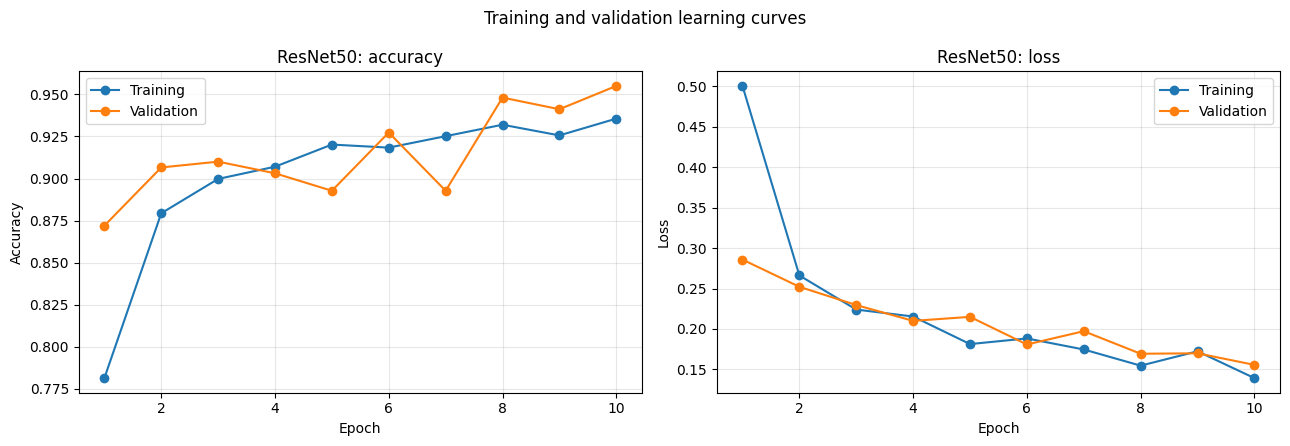

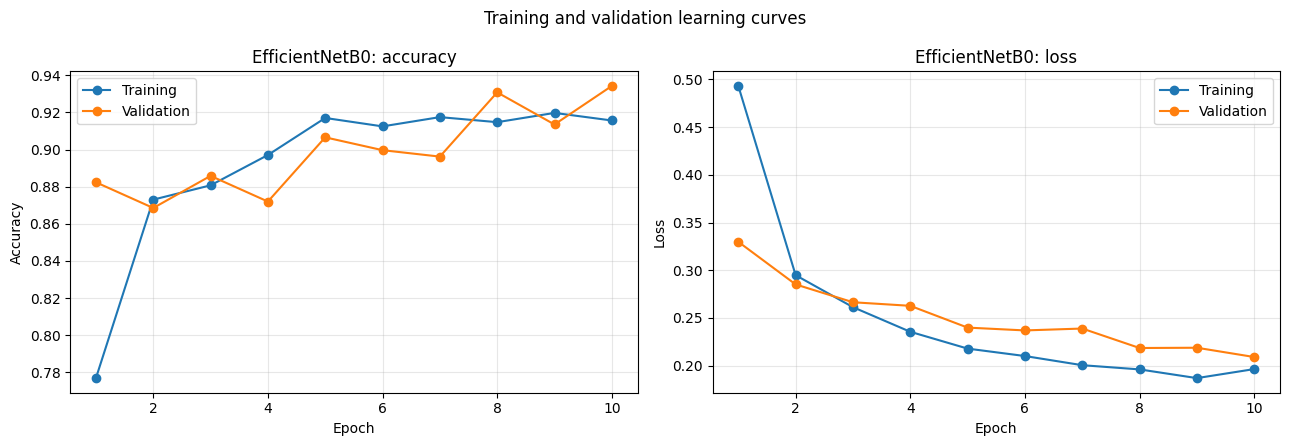

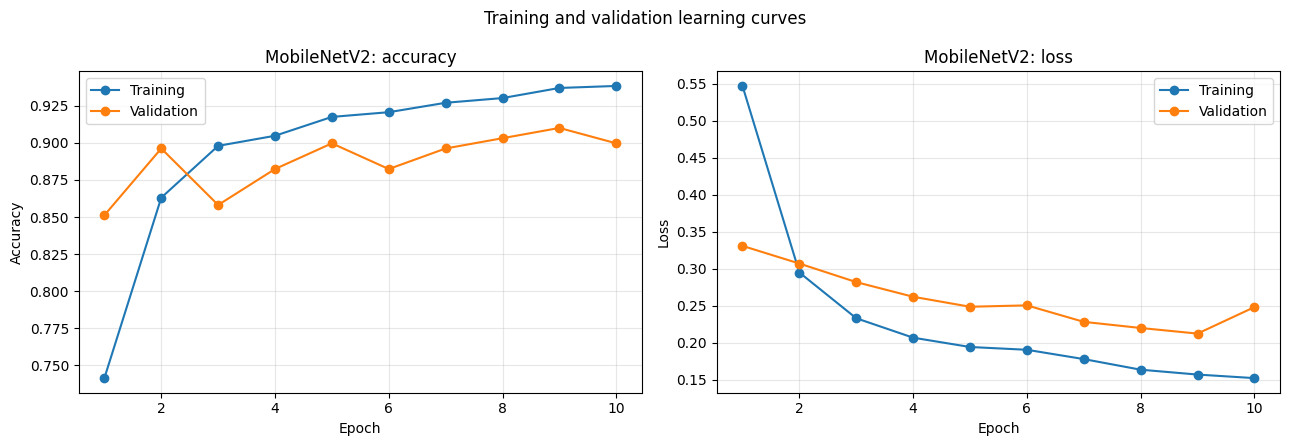

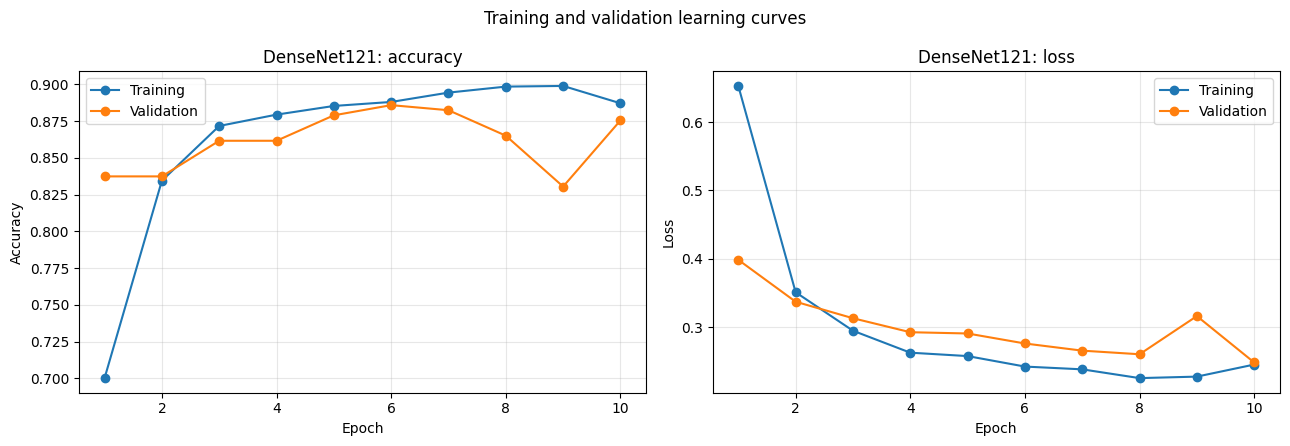

In [11]:
for model_name, history in trained_histories.items():
    history_data = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }
    with (HISTORIES_DIR / f"{model_name}_history.json").open("w") as file:
        json.dump(history_data, file, indent=2)

    epochs_seen = range(1, len(history.history["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(epochs_seen, history.history["accuracy"], marker="o", label="Training")
    axes[0].plot(epochs_seen, history.history["val_accuracy"], marker="o", label="Validation")
    axes[0].set(title=f"{model_name}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_seen, history.history["loss"], marker="o", label="Training")
    axes[1].plot(epochs_seen, history.history["val_loss"], marker="o", label="Validation")
    axes[1].set(title=f"{model_name}: loss", xlabel="Epoch", ylabel="Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle("Training and validation learning curves")
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / f"{model_name}_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 7. Evaluation on the independent test split

Accuracy is the share of all predictions that are correct. Precision, recall (sensitivity), F1, specificity, ROC-AUC, and average precision provide complementary views, especially if class counts differ.

For consistency, precision, recall, F1, specificity, ROC-AUC, and average precision are macro-averaged across classes. Macro averaging gives every class equal weight. Specificity is computed one-versus-rest for each class, then averaged. ROC and precision-recall curves are also drawn one-versus-rest. The validation macro F1 is used to select a model; test metrics are only reported after that selection and are not used to tune the models.


In [12]:
def collect_labels(dataset):
    return np.concatenate([labels.numpy() for _, labels in dataset]).astype(int)

y_test = collect_labels(test_ds)
y_val = collect_labels(val_ds)
class_indices = np.arange(NUM_CLASSES)

for split_name, labels in (("validation", y_val), ("test", y_test)):
    present_classes = set(np.unique(labels).tolist())
    if present_classes != set(class_indices.tolist()):
        raise ValueError(
            f"The {split_name} split must contain every class for macro ROC-AUC; "
            f"found class indices {sorted(present_classes)}"
        )

def calculate_specificity(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=class_indices)
    per_class_specificity = []
    for class_index in class_indices:
        true_positive = matrix[class_index, class_index]
        false_negative = matrix[class_index, :].sum() - true_positive
        false_positive = matrix[:, class_index].sum() - true_positive
        true_negative = matrix.sum() - true_positive - false_negative - false_positive
        denominator = true_negative + false_positive
        per_class_specificity.append(true_negative / denominator if denominator else np.nan)
    return float(np.nanmean(per_class_specificity))

def macro_roc_auc(y_true, probabilities):
    if NUM_CLASSES == 2:
        return float(roc_auc_score(y_true, probabilities[:, 1]))
    return float(
        roc_auc_score(
            y_true,
            probabilities,
            labels=class_indices,
            multi_class="ovr",
            average="macro",
        )
    )

def calculate_metrics(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {
        "Accuracy (%)": accuracy_score(y_true, predictions) * 100,
        "Precision - Macro (%)": precision_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "Recall / Sensitivity - Macro (%)": recall_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "Specificity - Macro (%)": calculate_specificity(y_true, predictions) * 100,
        "F1-score - Macro (%)": f1_score(y_true, predictions, average="macro", zero_division=0) * 100,
        "ROC-AUC - Macro": macro_roc_auc(y_true, probabilities),
        "Average Precision - Macro": average_precision_score(
            np.eye(NUM_CLASSES)[y_true], probabilities, average="macro"
        ),
    }

test_probabilities = {}
val_probabilities = {}
comparison_rows = []
per_class_reports = {}

for model_name, model in trained_models.items():
    print("Evaluating:", model_name)
    val_probabilities[model_name] = model.predict(val_ds, verbose=0)
    test_probabilities[model_name] = model.predict(test_ds, verbose=0)

    val_predictions = np.argmax(val_probabilities[model_name], axis=1)
    test_predictions = np.argmax(test_probabilities[model_name], axis=1)
    val_macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0) * 100
    test_metrics = calculate_metrics(y_test, test_probabilities[model_name])

    weights_path = MODELS_DIR / f"{model_name}_best.weights.h5"
    test_metrics.update({
        "Model": model_name,
        "Validation Macro F1 (%)": val_macro_f1,
        "Training Time (minutes)": training_seconds[model_name] / 60,
        "Model Weights (MB)": weights_path.stat().st_size / (1024 ** 2),
    })
    comparison_rows.append(test_metrics)

    per_class_reports[model_name] = pd.DataFrame(
        classification_report(
            y_test,
            test_predictions,
            labels=class_indices,
            target_names=class_names,
            output_dict=True,
            zero_division=0,
        )
    ).T
    per_class_reports[model_name].to_csv(METRICS_DIR / f"{model_name}_per_class_metrics.csv")

    prediction_table = pd.DataFrame({
        "sample_index": np.arange(len(y_test)),
        "true_label": [class_names[index] for index in y_test],
        "predicted_label": [class_names[index] for index in test_predictions],
        "confidence": np.max(test_probabilities[model_name], axis=1),
    })
    for class_index, class_name in enumerate(class_names):
        prediction_table[f"probability_{class_name}"] = test_probabilities[model_name][:, class_index]
    prediction_table.to_csv(PREDICTIONS_DIR / f"{model_name}_test_predictions.csv", index=False)

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
comparison_df = comparison_df.sort_values("Validation Macro F1 (%)", ascending=False)
display(comparison_df.round(3))
comparison_df.to_csv(METRICS_DIR / "model_comparison.csv")

Evaluating: ResNet50
Evaluating: EfficientNetB0
Evaluating: MobileNetV2
Evaluating: DenseNet121


,Accuracy (%),Precision - Macro (%),Recall / Sensitivity - Macro (%),Specificity - Macro (%),F1-score - Macro (%),ROC-AUC - Macro,Average Precision - Macro,Validation Macro F1 (%),Training Time (minutes),Model Weights (MB)
Model,,,,,,,,,,
ResNet50,93.151,93.195,93.195,96.004,93.195,0.983,0.966,95.576,14.099,90.519
EfficientNetB0,88.356,89.276,86.881,92.619,87.827,0.965,0.934,93.323,1.959,16.091
MobileNetV2,91.096,91.441,90.637,94.610,91.011,0.975,0.947,90.977,1.853,9.073
DenseNet121,88.356,89.078,87.140,92.717,87.938,0.964,0.937,87.295,3.144,27.948


### Model comparison and per-class metrics

Do not choose a model from test accuracy alone. The table is ordered by validation macro F1, which was computed without using the test labels. Review class-level precision, recall, and F1 alongside the test-set summary to see which classes are harder to recognize.


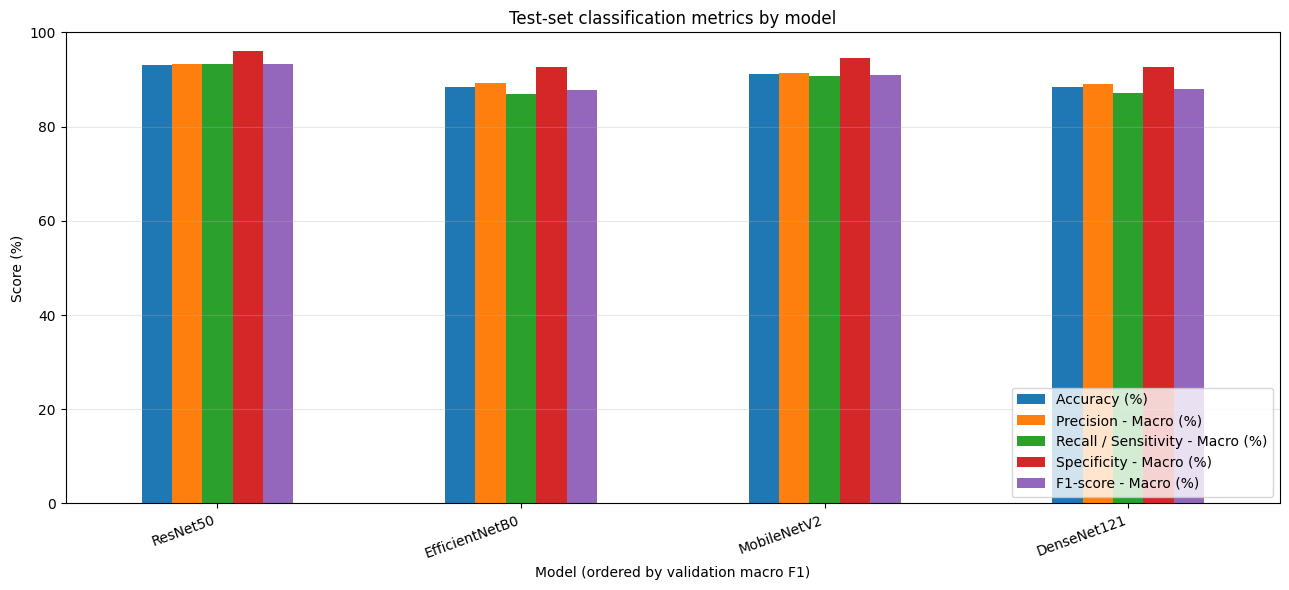


ResNet50: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.859,0.859,0.859,71.0
Malignant,0.937,0.937,0.937,158.0
Normal,1.000,1.000,1.000,63.0



EfficientNetB0: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.814,0.676,0.738,71.0
Malignant,0.865,0.930,0.896,158.0
Normal,1.000,1.000,1.000,63.0



MobileNetV2: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.836,0.789,0.812,71.0
Malignant,0.907,0.930,0.919,158.0
Normal,1.000,1.000,1.000,63.0



DenseNet121: test-set per-class precision, recall, and F1


,precision,recall,f1-score,support
Benign,0.803,0.690,0.742,71.0
Malignant,0.869,0.924,0.896,158.0
Normal,1.000,1.000,1.000,63.0


In [13]:
metric_columns = [
    "Accuracy (%)",
    "Precision - Macro (%)",
    "Recall / Sensitivity - Macro (%)",
    "Specificity - Macro (%)",
    "F1-score - Macro (%)",
]
ax = comparison_df[metric_columns].plot(kind="bar", figsize=(13, 6), ylim=(0, 100))
ax.set_title("Test-set classification metrics by model")
ax.set_xlabel("Model (ordered by validation macro F1)")
ax.set_ylabel("Score (%)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "model_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

for model_name, report in per_class_reports.items():
    print(f"\n{model_name}: test-set per-class precision, recall, and F1")
    display(report.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3))

### Confusion matrices

Rows show the true class and columns show the predicted class. Correct predictions lie on the diagonal; off-diagonal counts show which classes were confused. Each model gets its own matrix so the patterns remain readable.


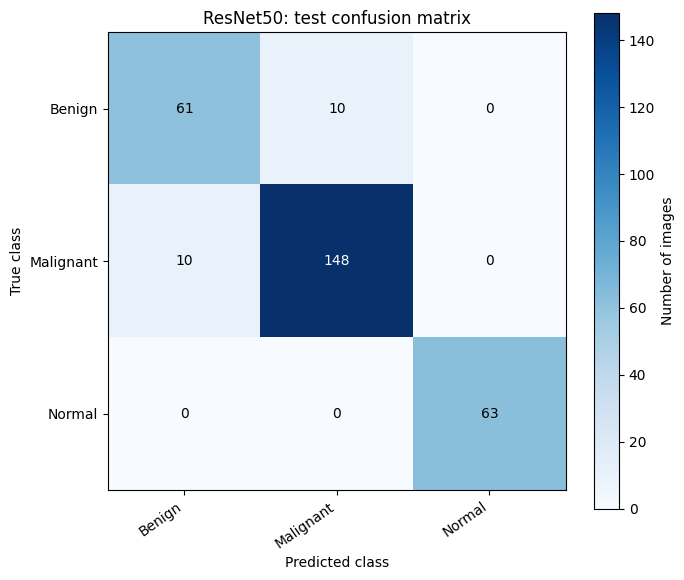

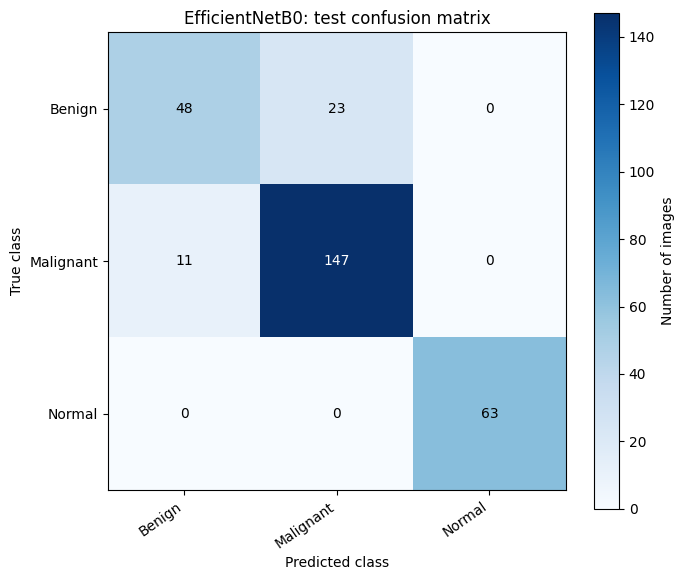

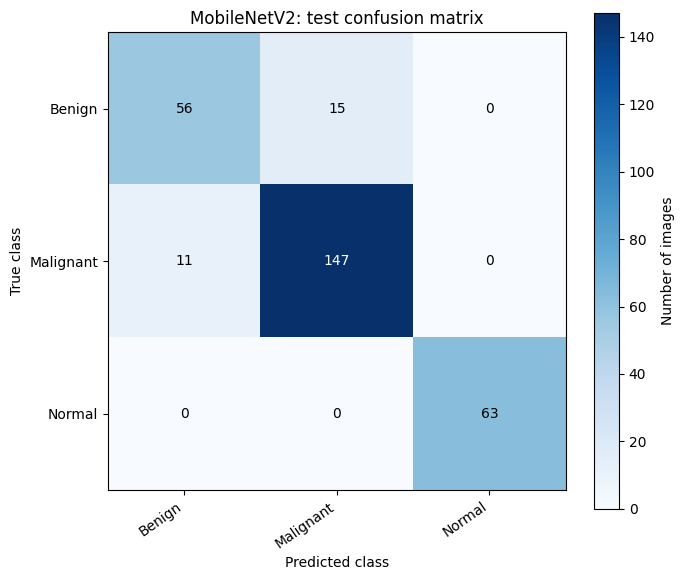

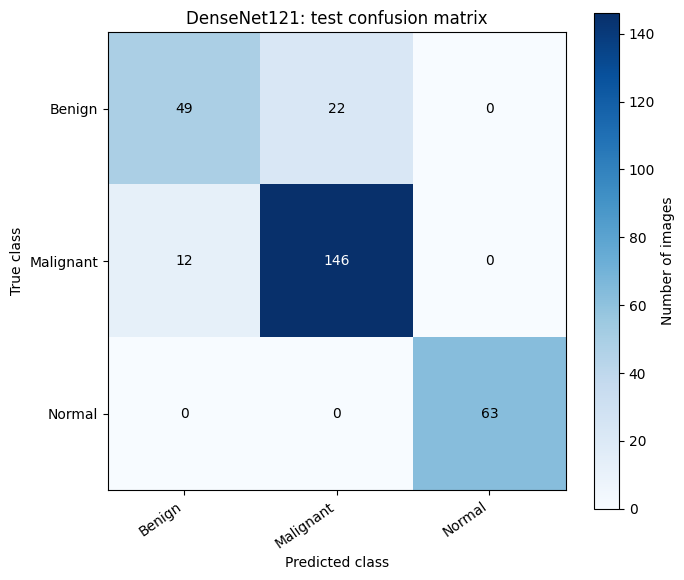

In [14]:
for model_name, probabilities in test_probabilities.items():
    predictions = np.argmax(probabilities, axis=1)
    matrix = confusion_matrix(y_test, predictions, labels=class_indices)
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set(
        title=f"{model_name}: test confusion matrix",
        xlabel="Predicted class",
        ylabel="True class",
        xticks=class_indices,
        yticks=class_indices,
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    threshold = matrix.max() / 2 if matrix.size else 0
    for row in range(NUM_CLASSES):
        for column in range(NUM_CLASSES):
            ax.text(
                column,
                row,
                str(matrix[row, column]),
                ha="center",
                va="center",
                color="white" if matrix[row, column] > threshold else "black",
            )
    fig.colorbar(image, ax=ax, label="Number of images")
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / f"{model_name}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### ROC curves

Each curve evaluates one class against all remaining classes. A curve closer to the top-left generally indicates better ranking of positives above negatives. AUC summarizes that ranking over thresholds; it does not identify a clinical decision threshold. Macro ROC-AUC in the comparison table gives each class equal weight.


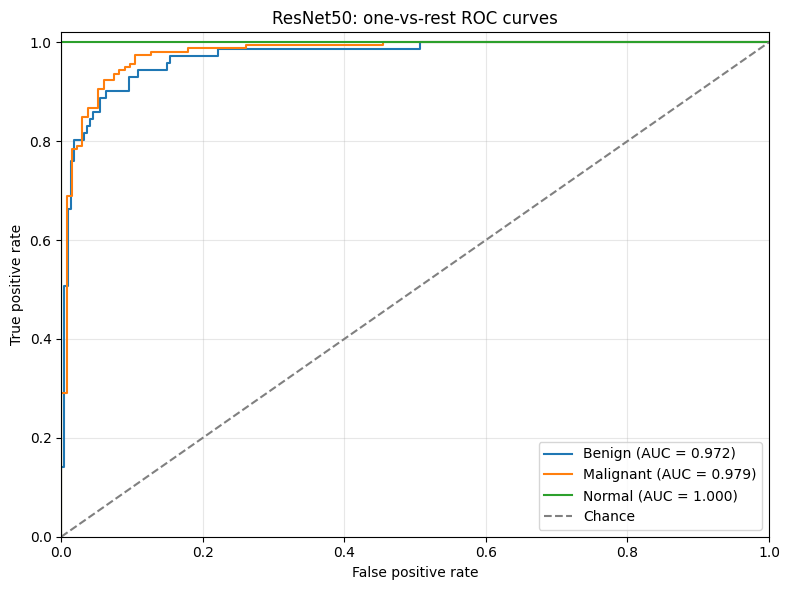

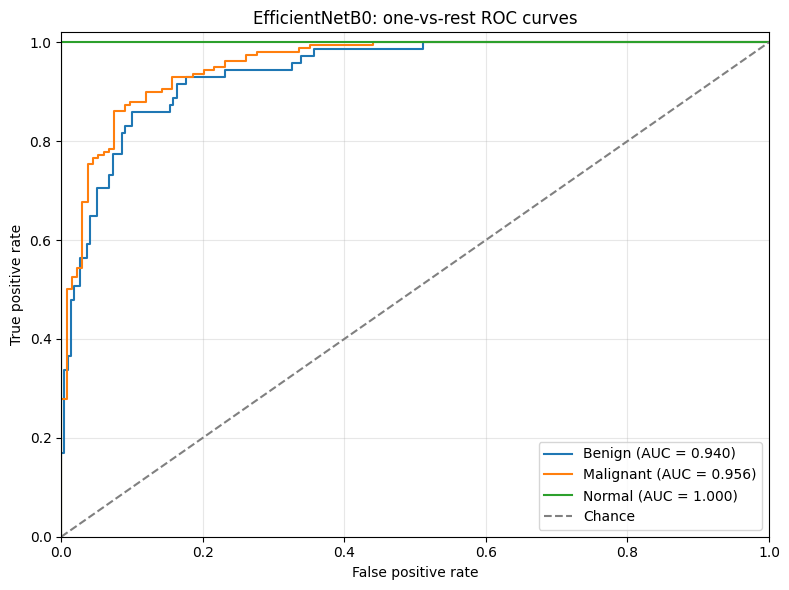

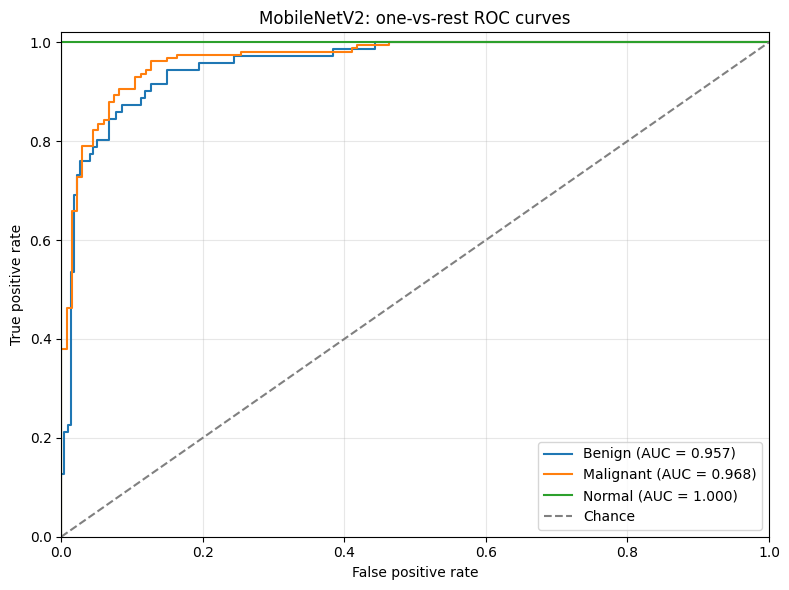

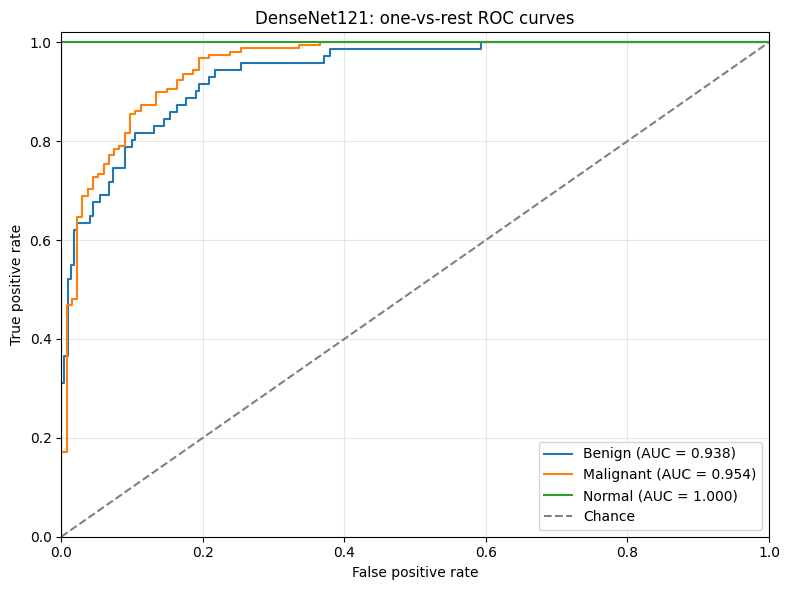

In [15]:
test_one_hot = np.eye(NUM_CLASSES)[y_test]
for model_name, probabilities in test_probabilities.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    for class_index, class_name in enumerate(class_names):
        false_positive_rate, true_positive_rate, _ = roc_curve(
            test_one_hot[:, class_index], probabilities[:, class_index]
        )
        class_auc = roc_auc_score(test_one_hot[:, class_index], probabilities[:, class_index])
        ax.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{class_name} (AUC = {class_auc:.3f})",
        )
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
    ax.set(
        title=f"{model_name}: one-vs-rest ROC curves",
        xlabel="False positive rate",
        ylabel="True positive rate",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / f"{model_name}_roc_curve.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Precision-recall curves

Precision-recall curves show the trade-off between finding more examples of a class (recall) and keeping its predictions correct (precision). They are useful when class frequencies differ. Each line is one class versus the rest; macro average precision gives the classes equal weight.


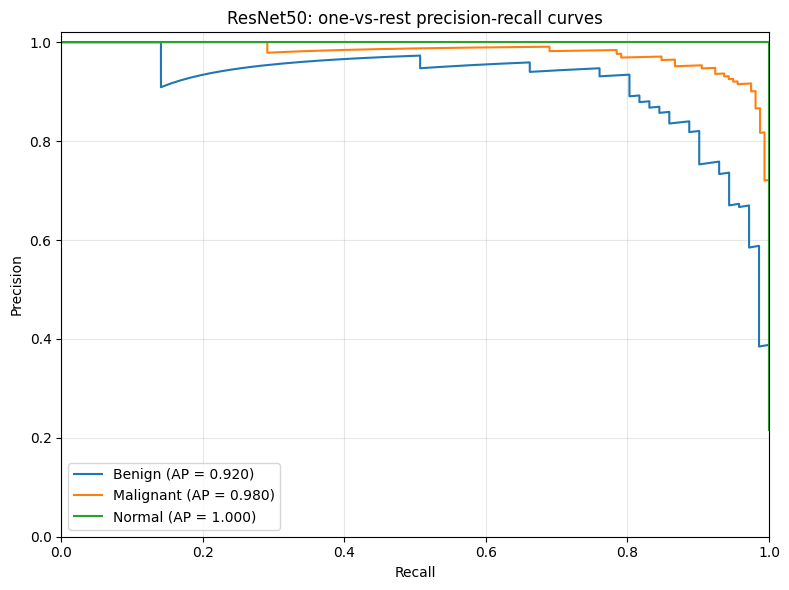

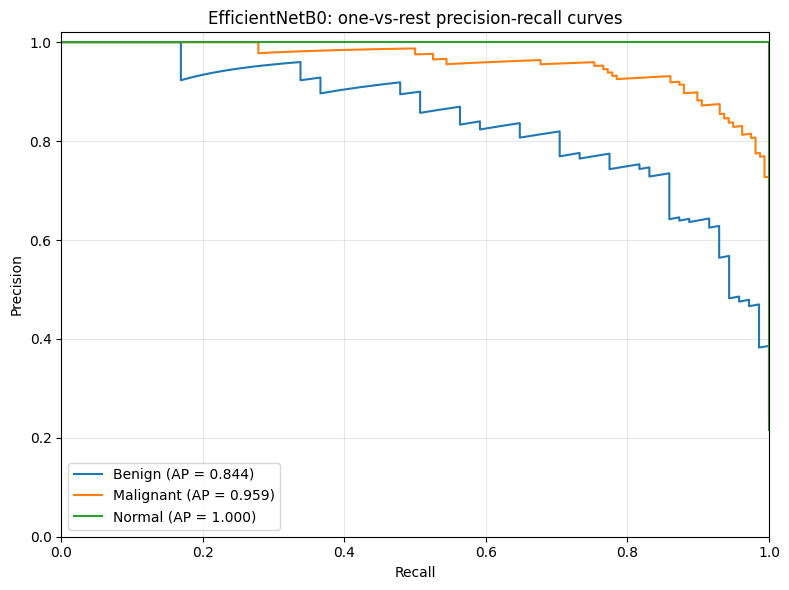

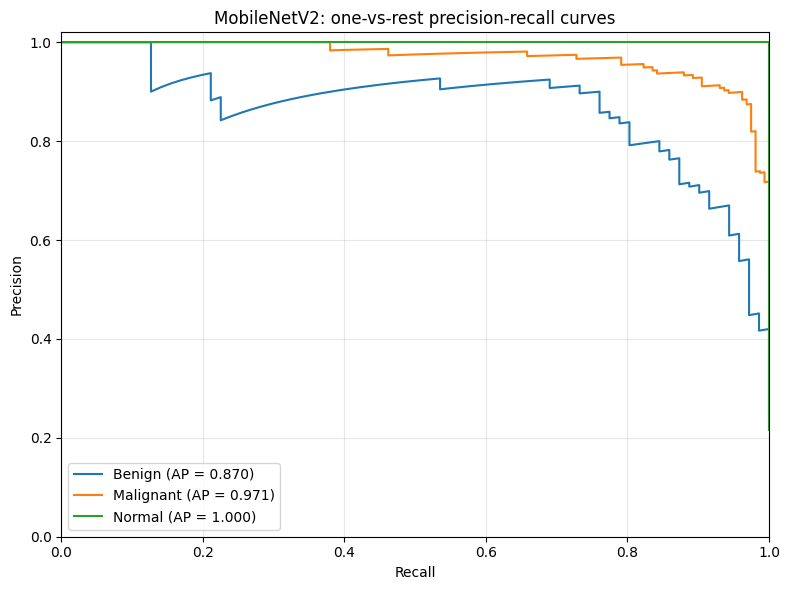

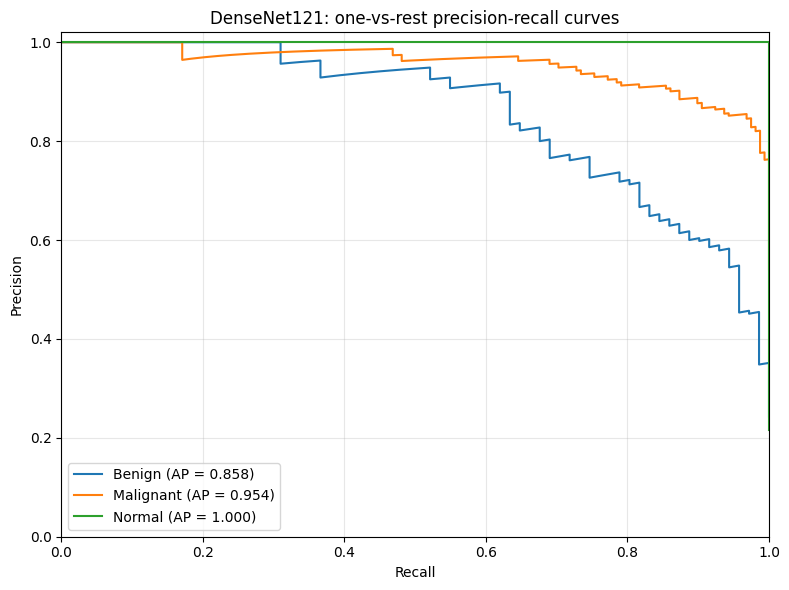

In [16]:
for model_name, probabilities in test_probabilities.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    for class_index, class_name in enumerate(class_names):
        precision_values, recall_values, _ = precision_recall_curve(
            test_one_hot[:, class_index], probabilities[:, class_index]
        )
        class_ap = average_precision_score(
            test_one_hot[:, class_index], probabilities[:, class_index]
        )
        ax.plot(recall_values, precision_values, label=f"{class_name} (AP = {class_ap:.3f})")
    ax.set(
        title=f"{model_name}: one-vs-rest precision-recall curves",
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / f"{model_name}_precision_recall_curve.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Training time and model size

These practical comparison charts complement the classification metrics. Training time depends on the available hardware and should not be treated as an intrinsic property of a model.


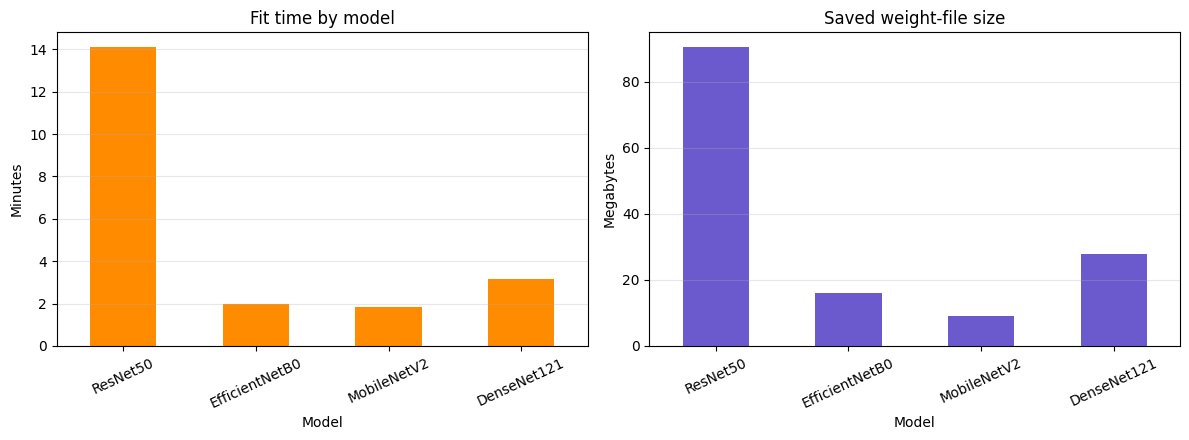

No learning-rate plot is shown because this experiment uses a constant learning rate.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison_df["Training Time (minutes)"].plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set(title="Fit time by model", xlabel="Model", ylabel="Minutes")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)

comparison_df["Model Weights (MB)"].plot(kind="bar", ax=axes[1], color="slateblue")
axes[1].set(title="Saved weight-file size", xlabel="Model", ylabel="Megabytes")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(GRAPHS_DIR / "training_time_and_model_size.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("No learning-rate plot is shown because this experiment uses a constant learning rate.")

## 8. Save experiment configuration and results

Each execution writes to its own timestamped run directory, keeping prior runs separate. The configuration records paths, class order, sample counts, important hyperparameters, model names, and software versions so the experiment can be interpreted later.


In [18]:
experiment_config = {
    "run_id": RUN_ID,
    "seed": SEED,
    "dataset_root": str(DATASET_ROOT),
    "split_directories": {
        "train": str(TRAIN_DIR),
        "validation": str(VAL_DIR),
        "test": str(TEST_DIR),
    },
    "class_names_in_label_order": class_names,
    "sample_counts_by_class": split_counts,
    "input_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_max": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "dropout_rate": DROPOUT_RATE,
    "early_stopping": {"monitor": "val_loss", "patience": EARLY_STOPPING_PATIENCE},
    "pretrained_weights": "ImageNet",
    "backbone_trainable": False,
    "data_augmentation": "No online augmentation; use the existing augmented V1 dataset",
    "models": MODEL_NAMES,
    "selection_metric": "validation macro F1",
    "test_set_used_for_selection": False,
    "tensorflow_version": tf.__version__,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "tensorflow_build_info": build_info,
    "visible_gpu_devices": [device.name for device in gpu_devices],
    "determinism_note": (
        "Seeds and deterministic TensorFlow operations are enabled where supported. "
        "Exact reproducibility across hardware and software versions is not guaranteed."
    ),
}

with (CONFIG_DIR / "experiment_config.json").open("w") as file:
    json.dump(experiment_config, file, indent=2, default=str)

comparison_df.to_json(METRICS_DIR / "model_comparison.json", orient="table", indent=2)
print("Experiment configuration and comparison results saved.")
print("Run folder:", RUN_DIR)

Experiment configuration and comparison results saved.
Run folder: /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311


## 9. Final summary and interpretation

The model below is identified using validation macro F1—not test accuracy. Compare its independent test metrics with the other models, inspect the per-class reports and confusion matrices, and review the learning curves for possible overfitting or underfitting. A small validation-to-training gap is only a useful clue; it does not prove that the model will generalize to new hospitals, scanners, or patients.

This dataset and experiment may have limitations such as limited sample diversity, uncertain patient-level separation, label noise, or class imbalance. Future work could verify patient-level splits, evaluate on an external dataset, test careful fine-tuning, tune a decision threshold on validation data, and report confidence intervals. Any change should be recorded as a separate experiment.


In [19]:
best_model_name = comparison_df["Validation Macro F1 (%)"].idxmax()
best_row = comparison_df.loc[best_model_name]
print("Model selected by validation macro F1:", best_model_name)
print(f"Validation macro F1: {best_row['Validation Macro F1 (%)']:.2f}%")
print(f"Test accuracy: {best_row['Accuracy (%)']:.2f}%")
print(f"Test macro precision: {best_row['Precision - Macro (%)']:.2f}%")
print(f"Test macro recall/sensitivity: {best_row['Recall / Sensitivity - Macro (%)']:.2f}%")
print(f"Test macro specificity: {best_row['Specificity - Macro (%)']:.2f}%")
print(f"Test macro F1: {best_row['F1-score - Macro (%)']:.2f}%")
print(f"Test macro ROC-AUC: {best_row['ROC-AUC - Macro']:.3f}")

history = trained_histories[best_model_name].history
training_validation_gap = history["accuracy"][-1] - history["val_accuracy"][-1]
print(f"\nFinal-epoch training minus validation accuracy: {training_validation_gap:.3f}")
if training_validation_gap > 0.10 and history["val_loss"][-1] > min(history["val_loss"]):
    print("The final epochs may show overfitting; inspect the learning curves.")
elif history["accuracy"][-1] < 0.70 and history["val_accuracy"][-1] < 0.70:
    print("Both final accuracies are relatively low; inspect for possible underfitting or data issues.")
else:
    print("No simple overfitting/underfitting rule is conclusive; inspect the learning curves and class metrics.")

print("\nAll run artifacts are under:", RUN_DIR)

Model selected by validation macro F1: ResNet50
Validation macro F1: 95.58%
Test accuracy: 93.15%
Test macro precision: 93.20%
Test macro recall/sensitivity: 93.20%
Test macro specificity: 96.00%
Test macro F1: 93.20%
Test macro ROC-AUC: 0.983

Final-epoch training minus validation accuracy: -0.019
No simple overfitting/underfitting rule is conclusive; inspect the learning curves and class metrics.

All run artifacts are under: /content/drive/MyDrive/Lung_Cancer_Classification_Results/run_20261109_093311
